# Single-stock risk report
Run after `01_data_cleaning.ipynb`. All report calculations use adjusted close; returns are daily log returns. Annualization assumes 252 trading days. Requested dates may exceed supplied coverage. The parameter cell is tagged for Papermill.


In [1]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"

In [2]:
# Parameters
ticker = "IBM"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/jingjian/Personal/UCB_MFE/Python/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Jing_Jian/data/data.db"


In [3]:
from pathlib import Path
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Validate report inputs.
ticker = ticker.strip().upper()
start = pd.Timestamp(start_date)
end = pd.Timestamp(end_date)

if not ticker:
    raise ValueError("Ticker must not be empty.")

if pd.isna(start) or pd.isna(end) or start > end:
    raise ValueError("Provide valid dates with start_date <= end_date.")

database = Path(db_path).resolve()

if not database.is_file():
    raise FileNotFoundError(f"Database not found: {database}")

# Read only the requested stock and date range.
with sqlite3.connect(database) as conn:
    stock = pd.read_sql_query(
        """
        SELECT ts, ticker, adj_close, volume
        FROM ohlc_hw_cleaned
        WHERE ticker = ?
          AND ts BETWEEN ? AND ?
        ORDER BY ts
        """,
        conn,
        params=(
            ticker,
            start.strftime("%Y-%m-%d"),
            end.strftime("%Y-%m-%d"),
        ),
        parse_dates=["ts"],
    )

if stock.empty:
    raise ValueError(
        f"No cleaned data for {ticker} between {start_date} and {end_date}."
    )

stock = stock.set_index("ts")

if len(stock) < 21:
    raise ValueError(
        f"{ticker} has {len(stock)} prices; "
        "at least 21 are required for 20 daily returns."
    )

print(
    f"{ticker} from {start:%Y-%m-%d} to {end:%Y-%m-%d}: "
    f"{len(stock)} trading days"
)
print(
    f"Actual coverage: {stock.index.min():%Y-%m-%d} "
    f"to {stock.index.max():%Y-%m-%d}"
)

display(stock.head())
display(stock.tail())
if stock.index.has_duplicates or stock.index.hasnans:
    raise ValueError("Observation dates must be valid and unique.")
if not (np.isfinite(stock["adj_close"]) & stock["adj_close"].gt(0)).all():
    raise ValueError("Adjusted prices must be finite and positive.")
if len(stock) < 50:
    print("Fewer than 50 prices: the 50-day moving average is unavailable.")
print("Coverage can differ across tickers; no trailing prices are extrapolated.")


IBM from 2024-06-01 to 2024-11-30: 126 trading days
Actual coverage: 2024-06-03 to 2024-11-29


,ticker,adj_close,volume
ts,,,
2024-06-03,IBM,162.57,2776100
2024-06-04,IBM,163.09,2594203
2024-06-05,IBM,164.63,3049400
2024-06-06,IBM,165.44,2207263
2024-06-07,IBM,167.22,3475500


,ticker,adj_close,volume
ts,,,
2024-11-22,IBM,222.97,5320740
2024-11-25,IBM,226.13,7189300
2024-11-26,IBM,228.83,4449543
2024-11-27,IBM,226.92,2995121
2024-11-29,IBM,227.41,2640300


Coverage can differ across tickers; no trailing prices are extrapolated.


## Risk calculations
Drawdown is measured from the running peak within the requested window. Sharpe uses the course approximation and a 2% annual risk-free rate.

In [4]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns from adjusted prices."""
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling sample volatility with full windows."""
    if window < 2:
        raise ValueError("Volatility window must be at least two.")
    return returns.rolling(window, min_periods=window).std(ddof=1) * np.sqrt(252)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown, rather than the running worst drawdown."""
    return prices / prices.cummax() - 1


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate the course annualized Sharpe approximation; undefined is NaN."""
    values = returns.dropna()
    std = values.std(ddof=1)
    if len(values) < 2 or not np.isfinite(std) or std <= 0:
        return np.nan
    return (values.mean() * 252 - risk_free_rate) / (std * np.sqrt(252))


stock["log_return"] = calculate_returns(stock["adj_close"])
stock["rolling_volatility"] = calculate_volatility(stock["log_return"])
stock["drawdown"] = calculate_max_drawdown(stock["adj_close"])
stock["ma_50"] = stock["adj_close"].rolling(50, min_periods=50).mean()
returns = stock["log_return"].dropna()
sharpe_ratio = calculate_sharpe_ratio(returns)
max_drawdown = stock["drawdown"].min()
mean_rolling_volatility = stock["rolling_volatility"].mean()
display(stock.head(25))

,ticker,adj_close,volume,log_return,rolling_volatility,drawdown,ma_50
ts,,,,,,,
2024-06-03,IBM,162.57,2776100,NaN,NaN,0.000000,NaN
2024-06-04,IBM,163.09,2594203,0.003194,NaN,0.000000,NaN
2024-06-05,IBM,164.63,3049400,0.009398,NaN,0.000000,NaN
2024-06-06,IBM,165.44,2207263,0.004908,NaN,0.000000,NaN
2024-06-07,IBM,167.22,3475500,0.010702,NaN,0.000000,NaN
2024-06-10,IBM,167.58,3444700,0.002151,NaN,0.000000,NaN
2024-06-11,IBM,166.54,2951300,-0.006225,NaN,-0.006206,NaN
2024-06-12,IBM,166.22,3522700,-0.001923,NaN,-0.008116,NaN
2024-06-13,IBM,166.34,3525717,0.000722,NaN,-0.007399,NaN


## Risk charts
Price segments use the ending observation’s rolling volatility: red above the report mean, green at or below it, and gray during warm-up. Coloring and the mean threshold are retrospective. Rolling warm-up gaps remain missing.

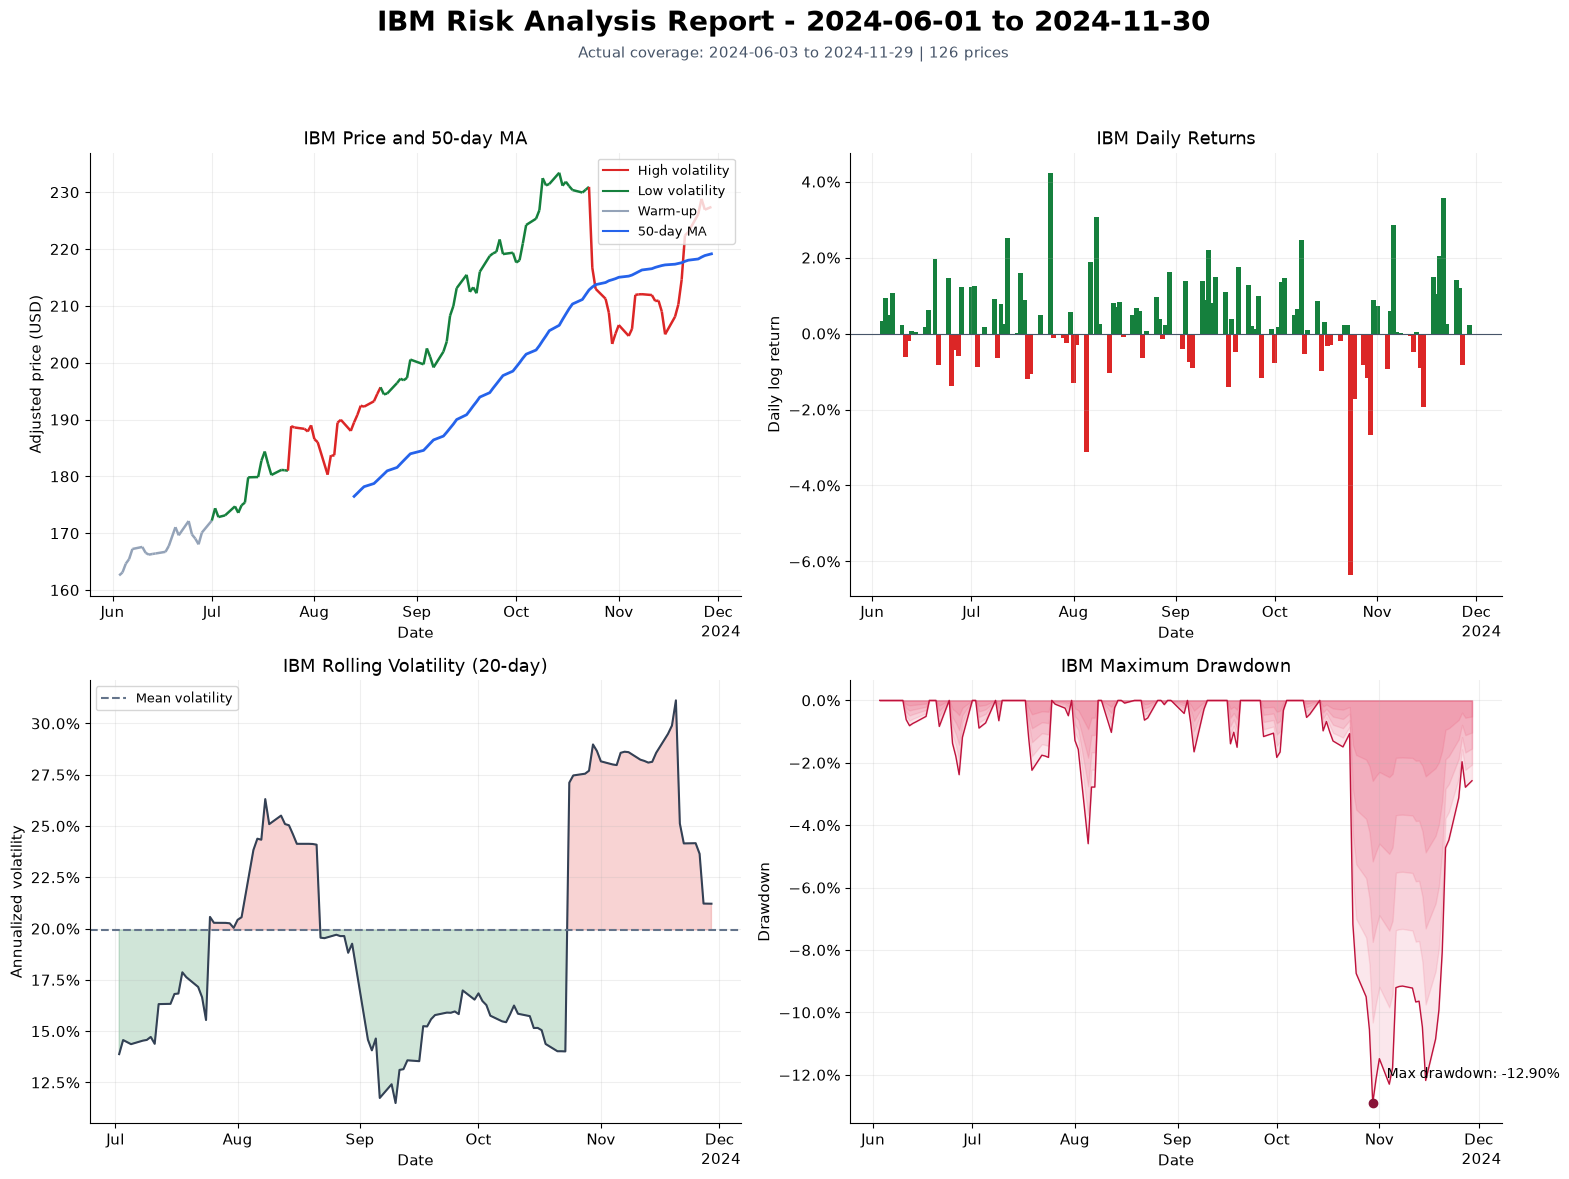

In [5]:
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import matplotlib.dates as mdates

with plt.rc_context({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False}):
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    dates = stock.index
    x = mdates.date2num(dates.to_pydatetime())
    prices = stock["adj_close"].to_numpy()
    vol = stock["rolling_volatility"]
    points = np.column_stack([x, prices])
    segments = np.stack([points[:-1], points[1:]], axis=1)
    colors = ["#94a3b8" if pd.isna(v) else
              "#dc2626" if v > mean_rolling_volatility else "#15803d"
              for v in vol.iloc[1:]]
    ax = axes[0, 0]
    ax.add_collection(LineCollection(segments, colors=colors, linewidths=1.8))
    ax.plot(dates, stock["ma_50"], color="#2563eb", linewidth=2, label="50-day MA")
    ax.autoscale_view()
    ax.xaxis_date()
    ax.legend(handles=[Line2D([], [], color=c, label=l) for c, l in
                       [("#dc2626", "High volatility"), ("#15803d", "Low volatility"),
                        ("#94a3b8", "Warm-up"), ("#2563eb", "50-day MA")]], fontsize=9)
    ax.set(title=f"{ticker} Price and 50-day MA", ylabel="Adjusted price (USD)")

    ax = axes[0, 1]
    ax.bar(dates, stock["log_return"], width=1.5,
           color=np.where(stock["log_return"].ge(0), "#15803d", "#dc2626"))
    ax.axhline(0, color="#475569", linewidth=0.8)
    ax.set(title=f"{ticker} Daily Returns", ylabel="Daily log return")
    ax.yaxis.set_major_formatter(PercentFormatter(1))

    ax = axes[1, 0]
    ax.plot(dates, vol, color="#334155", linewidth=1.5)
    ax.axhline(mean_rolling_volatility, color="#64748b", linestyle="--", label="Mean volatility")
    ax.fill_between(dates, mean_rolling_volatility, vol,
                    where=vol.gt(mean_rolling_volatility), color="#dc2626", alpha=0.2, interpolate=True)
    ax.fill_between(dates, vol, mean_rolling_volatility,
                    where=vol.le(mean_rolling_volatility), color="#15803d", alpha=0.2, interpolate=True)
    ax.set(title=f"{ticker} Rolling Volatility (20-day)", ylabel="Annualized volatility")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(fontsize=9)

    ax = axes[1, 1]
    dd = stock["drawdown"]
    for fraction in np.linspace(0.2, 1, 5):
        ax.fill_between(dates, dd * fraction, 0, color="#e11d48", alpha=0.10)
    ax.plot(dates, dd, color="#be123c", linewidth=1)
    worst_date = dd.idxmin()
    ax.scatter([worst_date], [dd.loc[worst_date]], color="#881337", zorder=5)
    ax.annotate(f"Max drawdown: {dd.min():.2%}",
                xy=(worst_date, dd.min()), xytext=(10, 18),
                textcoords="offset points", fontsize=10)
    ax.set(title=f"{ticker} Maximum Drawdown", ylabel="Drawdown")
    ax.yaxis.set_major_formatter(PercentFormatter(1))

    for ax in axes.flat:
        ax.grid(True, alpha=0.2)
        ax.set_xlabel("Date")
        locator = mdates.AutoDateLocator()
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=20, fontweight="bold")
    fig.text(0.5, 0.94,
             f"Actual coverage: {dates.min():%Y-%m-%d} to {dates.max():%Y-%m-%d} | {len(stock)} prices",
             ha="center", color="#475569")
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

## Summary statistics
Fractions are retained in named outputs; percentages are display formatting only. Positive-day frequency includes zero-return days in its denominator. Annualized volatility uses the whole period and differs from mean rolling volatility.

In [6]:
metrics = {
    "Total Return": stock["adj_close"].iloc[-1] / stock["adj_close"].iloc[0] - 1,
    "Annualized Return": np.expm1(returns.sum() * 252 / len(returns)),
    "Annualized Volatility": returns.std(ddof=1) * np.sqrt(252),
    "Sharpe Ratio": sharpe_ratio,
    "Maximum Drawdown": max_drawdown,
    "Best Day": returns.max(),
    "Worst Day": returns.min(),
    "Positive Days": returns.gt(0).mean(),
    "Average Up Day": returns.loc[returns.gt(0)].mean(),
    "Average Down Day": returns.loc[returns.lt(0)].mean(),
}
summary_table = pd.DataFrame({
    "Metric": list(metrics),
    "Value": ["N/A" if not np.isfinite(value) else
              f"{value:.2f}" if name == "Sharpe Ratio" else f"{value:+.2%}"
              for name, value in metrics.items()],
})
display(summary_table.set_index("Metric"))

# Named outputs for Part 3; no extraction of display-formatted percentages.
import scrapbook as sb
report_summary = {
    "ticker": ticker,
    "start_date": start.strftime("%Y-%m-%d"),
    "end_date": end.strftime("%Y-%m-%d"),
    "actual_start": stock.index.min().strftime("%Y-%m-%d"),
    "actual_end": stock.index.max().strftime("%Y-%m-%d"),
    "n_prices": len(stock),
    "avg_daily_return": float(returns.mean()),
    "avg_volatility": float(mean_rolling_volatility),
    "max_drawdown": float(max_drawdown),
    "sharpe_ratio": float(sharpe_ratio),
    "total_return": float(metrics["Total Return"]),
}
# Keep Scrapbook's machine-readable data and add a standard text fallback.
from IPython.utils.capture import capture_output

for name, value in report_summary.items():
    with capture_output() as captured:
        sb.glue(name, value)
    for saved_output in captured.outputs:
        saved_output.data["text/plain"] = f"Saved batch metric: {name} = {value}"
        saved_output.display()


,Value
Metric,
Total Return,+39.88%
Annualized Return,+96.73%
Annualized Volatility,+20.42%
Sharpe Ratio,3.22
Maximum Drawdown,-12.90%
Best Day,+4.24%
Worst Day,-6.37%
Positive Days,+63.20%
Average Up Day,+0.95%


Saved batch metric: ticker = IBM

Saved batch metric: start_date = 2024-06-01

Saved batch metric: end_date = 2024-11-30

Saved batch metric: actual_start = 2024-06-03

...

Saved batch metric: avg_daily_return = 0.0026851670198176467

Saved batch metric: avg_volatility = 0.199331817137354

Saved batch metric: max_drawdown = -0.12903778596521287

Saved batch metric: sharpe_ratio = 3.216395488583877

Saved batch metric: total_return = 0.3988435750753523